# Your first RL policy in Isaac Lab

**Goal of this notebook:** go from *"I studied PPO a while ago"* to *"I can build, train, debug and explain
an RL task in Isaac Lab"*. By the end you will have:

1. refreshed the RL and **PPO** theory you need (with small code demos),
2. learned how **Isaac Lab** is organised and how a simulation actually runs,
3. **written your own task** (cartpole) from scratch: observations, actions, rewards, terminations, resets,
4. **trained it with PPO**, watched it, read its training curves,
5. run a **reward-design experiment** and seen a policy exploit a badly designed reward,
6. understood the **manager-based** workflow and trained a **Unitree Go2** to walk,
7. learned the **terminal workflow** you will use for longer trainings,
8. collected **interview questions** with answers.

| Part | Topic | Time to run |
|---|---|---|
| 0 | Setup | ~1 min |
| 1 | RL refresher | reading |
| 2 | PPO explained | reading + tiny demos |
| 3 | Isaac Lab: scenes, assets, the simulation loop | ~2 min |
| 4 | Your own task: cartpole (Direct workflow) + PPO training + reward experiment | ~6 min |
| 5 | Manager-based workflow: train a Go2 to walk | ~6 min |
| 6 | Terminal workflow | reading |
| 7 | Recap and interview questions | reading |

**How to use it:** run the cells **in order** with `Shift+Enter`. Read the text before each code cell, and
when a cell says *"Predict first"*, write your prediction down before running it. If something breaks,
`Kernel → Restart Kernel` and run from the top (Part 0 is required for everything after it).

> Everything here runs on the **Newton** physics engine on your GPU. Videos are rendered with a simulated
> camera and shown right under the cells, so no viewer window is needed.

---
# Part 0 — Setup

This cell imports Isaac Lab and defines three small helpers used throughout:

- `quiet_simulation()` hides the (very verbose) simulator logs, and prints them only if something fails,
- `save_video(frames, name)` writes a list of RGB frames to `videos/<name>.mp4` and shows it here,
- `SIM_ARGS` tells Isaac Lab to run **without** a viewer window (we record videos instead).

In [1]:
import os
from contextlib import contextmanager, redirect_stderr, redirect_stdout
from pathlib import Path
from tempfile import TemporaryFile

import warp as wp

wp.config.enable_backward = False  # we never differentiate through physics here; saves compile time
os.environ.pop("DISPLAY", None)  # no viewer windows: we record videos with a simulated camera

import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Video, display
from wurlitzer import STDOUT, pipes

import isaaclab

# the repository folder (logs/ and videos/ go there, wherever this notebook is)
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "env.sh").is_file()), Path.cwd())
(ROOT / "videos").mkdir(exist_ok=True)
SIM_ARGS = {"visualizer": None, "visualizer_explicit": True}  # headless: no viewer window

print(f"torch {torch.__version__} | GPU: {torch.cuda.get_device_name(0)} | Isaac Lab imported from {Path(isaaclab.__file__).parent}")


@contextmanager
def quiet_simulation():
    # Hide Python *and* C++ simulator logs; print them if the block raises an error.
    with TemporaryFile(mode="w+", encoding="utf-8") as logs:
        try:
            with redirect_stdout(logs), redirect_stderr(logs), pipes(stdout=logs, stderr=STDOUT):
                yield
        except BaseException:
            logs.seek(0)
            print(logs.read()[-20000:], end="")
            raise


def save_video(frames, name, fps=30, width=560):
    # Write RGB frames (H x W x 3, uint8) to videos/<name>.mp4 and display the clip.
    path = ROOT / "videos" / f"{name}.mp4"
    imageio.mimsave(path, frames, fps=fps, macro_block_size=1)
    display(Video(str(path), embed=True, width=width, html_attributes="controls loop muted autoplay playsinline"))
    return path

torch 2.11.0+cu130 | GPU: NVIDIA GeForce RTX 5070 Laptop GPU | Isaac Lab imported from /home/andres/isaaclab/IsaacLab/source/isaaclab/isaaclab


> **Note:** the first time a simulation starts, NVIDIA **Warp** (the GPU language Newton is written in)
> compiles its kernels, so the first simulation cell of the notebook takes noticeably longer. Later runs
> load the compiled kernels from a cache.

---
# Part 1 — Reinforcement learning in 10 minutes

## 1.1 The problem: a Markov Decision Process (MDP)

At every time step $t$ the agent (our robot controller):

1. receives an **observation** $o_t$ (e.g. joint angles, body velocity),
2. picks an **action** $a_t$ from its **policy** $\pi_\theta(a_t \mid o_t)$, a neural network with weights $\theta$,
3. the world (here: the simulator) moves to the next state and returns a **reward** $r_t$,
4. until the episode ends: a **termination** (failure, e.g. the robot fell) or a **time-out**.

The goal is to maximise the expected **return**, the discounted sum of future rewards:

$$G_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \dots = \sum_{k\ge 0} \gamma^k r_{t+k}, \qquad J(\theta) = \mathbb{E}_{\pi_\theta}[G_0]$$

The **discount** $\gamma \in [0,1)$ (we use 0.99) makes rewards far in the future count less. With
$\gamma = 0.99$ the "effective horizon" is about $1/(1-\gamma) = 100$ steps, i.e. 2 s at a 50 Hz policy.

## 1.2 Value functions and the advantage

- **Value** $V^\pi(s)$: the expected return from state $s$ if you follow $\pi$. *"How good is this situation?"*
- **Action value** $Q^\pi(s,a)$: expected return if you take action $a$ now, then follow $\pi$.
- **Advantage** $A^\pi(s,a) = Q^\pi(s,a) - V^\pi(s)$: *"how much better was this action than what I usually do here?"*

The advantage is the key quantity in PPO: push up the probability of actions with $A>0$, push down those with $A<0$.

## 1.3 What is special about robot RL in Isaac Lab

| RL concept | In a robot task | Who defines it |
|---|---|---|
| Observation | joint positions/velocities, body velocity, gravity direction, commands, terrain heights… | **you** (task design) |
| Action | usually **joint position targets** that a PD controller tracks | **you** |
| Reward | a weighted sum of terms ("track the velocity", "don't jerk", "don't fall"…) | **you** — the hardest part |
| Transition | physics | the simulator |
| Policy | small MLP (e.g. 512-256-128) | the RL algorithm learns it |

**Why GPU simulation matters:** PPO is *on-policy*: it can only learn from data collected with the *current*
policy, then must throw it away and collect more. So it needs a huge amount of fresh experience. Isaac Lab
simulates **thousands of robots in parallel on the GPU** (we will use 4096), giving ~100 000 transitions in
well under a second. This is the idea behind *"learning to walk in minutes"* (Rudin et al., 2021, ETH RSL).

---
# Part 2 — PPO, step by step

PPO (*Proximal Policy Optimization*, Schulman et al., 2017) is the workhorse of robot RL: simple, stable,
and it parallelises extremely well. We build it up in five steps.

## 2.1 Policy gradient: the core idea

We want to change $\theta$ to increase $J(\theta)$. The **policy gradient theorem** gives

$$\nabla_\theta J(\theta) = \mathbb{E}\Big[\, \nabla_\theta \log \pi_\theta(a_t \mid o_t)\; A_t(o_t, a_t) \,\Big]$$

Read it as: *for every action we took, nudge the network to make that action more likely, by an amount
proportional to how much better than expected it turned out ($A_t$).* Bad actions ($A_t<0$) get less likely.

## 2.2 Actor and critic

- The **actor** is the policy. For continuous control it outputs the **mean** $\mu_\theta(o)$ of a Gaussian,
  and a learned **standard deviation** $\sigma$. Actions are sampled $a \sim \mathcal{N}(\mu, \sigma^2)$ during
  training; the randomness is the **exploration**. At deployment we just use the mean.
- The **critic** is a second network $V_\phi(o)$ that predicts the value. We need it to compute advantages.

In RSL-RL both are MLPs (for the Go2: `[512, 256, 128]`, ELU activations), and `init_std=1.0` sets the
initial exploration noise.

## 2.3 Estimating the advantage: GAE

We never know $A_t$ exactly; we estimate it from the collected rewards and the critic. The **TD error**

$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$$

is a one-step estimate (*"reward I got + value of where I landed − value I expected"*). **Generalized
Advantage Estimation** (Schulman et al., 2015) mixes multi-step estimates with a parameter $\lambda$:

$$\hat A_t = \sum_{l \ge 0} (\gamma\lambda)^l \, \delta_{t+l}$$

- $\lambda = 0$: only one step, low variance but biased by critic errors,
- $\lambda = 1$: full Monte-Carlo return minus baseline, unbiased but noisy,
- $\lambda = 0.95$ (our setting): a good compromise.

The **value target** used to train the critic is $\hat R_t = \hat A_t + V(s_t)$.

Let's compute GAE by hand on a toy 6-step episode. The robot gets reward 1 per step, but the critic is
too pessimistic early on.

In [2]:
def gae(rewards, values, last_value, dones, gamma=0.99, lam=0.95):
    # Backwards pass exactly as in RSL-RL's rollout storage.
    advantages = np.zeros_like(rewards)
    next_adv, next_value = 0.0, last_value
    for t in reversed(range(len(rewards))):
        not_done = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_value * not_done - values[t]  # TD error
        next_adv = delta + gamma * lam * not_done * next_adv  # discounted sum of TD errors
        advantages[t] = next_adv
        next_value = values[t]
    return advantages


rewards = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
values = np.array([2.0, 2.5, 3.0, 3.5, 4.0, 4.5])  # critic's predictions V(s_t)
dones = np.zeros(6)
last_value = 5.0  # V(s_6): the episode continues after our 6-step window

for lam in (0.0, 0.95, 1.0):
    adv = gae(rewards, values, last_value, dones, lam=lam)
    print(f"lambda={lam:4}: advantages = {np.round(adv, 2)}   value targets = {np.round(adv + values, 2)}")

lambda= 0.0: advantages = [1.48 1.47 1.46 1.46 1.46 1.45]   value targets = [3.48 3.97 4.46 4.96 5.46 5.95]
lambda=0.95: advantages = [7.57 6.48 5.33 4.11 2.82 1.45]   value targets = [9.57 8.98 8.33 7.61 6.82 5.95]
lambda= 1.0: advantages = [8.56 7.16 5.74 4.32 2.89 1.45]   value targets = [10.56  9.66  8.74  7.82  6.89  5.95]


All advantages are positive: the critic underestimated how good these states are, so the actions taken
are reinforced, and the critic will be trained towards the (higher) value targets. Notice how $\lambda$
changes how much later rewards influence earlier advantages.

## 2.4 The "proximal" part: don't change the policy too much

Plain policy gradient has a nasty failure mode: one too-large update can wreck the policy, and since the
next batch of data is collected *with that broken policy*, it may never recover. PPO limits each update.
It uses the **probability ratio** between the new and the old (data-collecting) policy,

$$r_t(\theta) = \frac{\pi_\theta(a_t \mid o_t)}{\pi_{\theta_\text{old}}(a_t \mid o_t)}$$

and the **clipped surrogate objective** (to be maximised):

$$L^\text{CLIP}(\theta) = \mathbb{E}\Big[\min\big(r_t(\theta)\,\hat A_t,\;\; \operatorname{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)\,\hat A_t\big)\Big], \qquad \epsilon = 0.2$$

Once an action has been made 20% more likely (for $A>0$) or 20% less likely (for $A<0$), the gradient for
that sample becomes zero: there is no incentive to push further on this batch. The plot shows it:

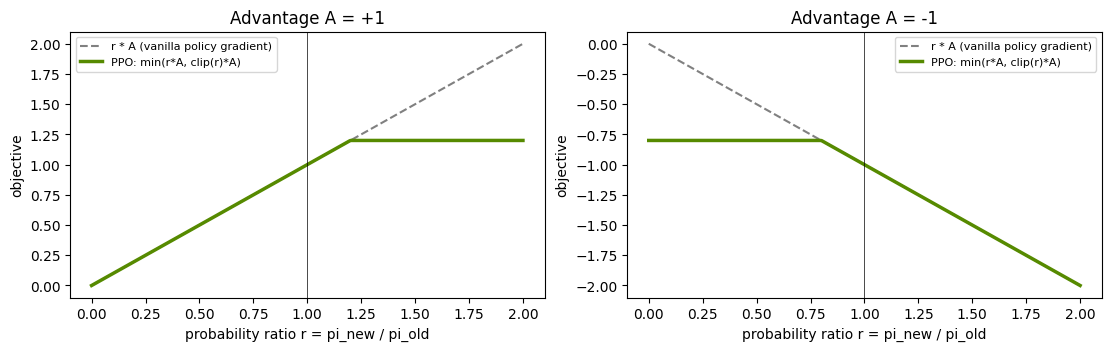

In [3]:
ratio = np.linspace(0.0, 2.0, 400)
eps = 0.2
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained")
for ax, advantage in zip(axes, (+1.0, -1.0)):
    unclipped = ratio * advantage
    clipped = np.clip(ratio, 1 - eps, 1 + eps) * advantage
    ax.plot(ratio, unclipped, "--", color="grey", label="r * A (vanilla policy gradient)")
    ax.plot(ratio, np.minimum(unclipped, clipped), color="#568a00", lw=2.5, label="PPO: min(r*A, clip(r)*A)")
    ax.axvline(1.0, color="k", lw=0.5)
    ax.set(title=f"Advantage A = {advantage:+.0f}", xlabel="probability ratio r = pi_new / pi_old", ylabel="objective")
    ax.legend(fontsize=8)
plt.show()

- **Left ($A>0$, good action):** the objective rises as the action gets more likely, but goes **flat** after
  $r = 1.2$: no reward for over-committing.
- **Right ($A<0$, bad action):** it rewards making the action less likely, but goes flat below $r = 0.8$.

## 2.5 The full PPO loss and training loop

The loss minimised in practice (RSL-RL) combines three parts:

$$\mathcal{L} = -L^\text{CLIP} \;+\; c_v \,\big(V_\phi(o_t) - \hat R_t\big)^2 \;-\; c_e \,\mathcal{H}[\pi_\theta(\cdot\mid o_t)]$$

policy term + critic regression (`value_loss_coef`) − entropy bonus (`entropy_coef`, keeps exploring).

One **iteration** of PPO (this is exactly what `runner.learn()` does):

```text
for iteration in range(max_iterations):
    # 1) ROLLOUT: run the current policy in all N parallel environments for T steps
    for t in range(num_steps_per_env):          # T, e.g. 24
        actions = actor.sample(obs)             # Gaussian sampling = exploration
        obs, rewards, dones = env.step(actions) # N robots simulated in parallel on the GPU
        storage.add(...)
    # 2) ADVANTAGES: GAE with the critic (backwards in time, as in our toy example)
    # 3) UPDATE: num_learning_epochs passes over the N*T samples, split into num_mini_batches
    for epoch in range(num_learning_epochs):
        for batch in storage.mini_batches(num_mini_batches):
            loss = -clipped_surrogate + value_loss_coef*value_loss - entropy_coef*entropy
            gradient step (with max_grad_norm clipping); adapt learning rate with KL if schedule="adaptive"
    # 4) throw the data away (on-policy!) and repeat
```

## 2.6 The hyperparameters you will see in every config

| RSL-RL name | Typical | Meaning |
|---|---|---|
| `num_steps_per_env` | 16–24 | rollout length $T$ per env per iteration. Batch = `num_envs × T` (4096 × 24 ≈ 98k) |
| `num_learning_epochs` | 5 | how many times we reuse each batch |
| `num_mini_batches` | 4 | batch split for SGD steps → 5 × 4 = 20 gradient steps per iteration |
| `clip_param` | 0.2 | PPO's $\epsilon$ |
| `gamma` | 0.99 | discount |
| `lam` | 0.95 | GAE $\lambda$ |
| `value_loss_coef` | 1.0 | weight of the critic loss |
| `entropy_coef` | 0.005–0.01 | exploration bonus |
| `learning_rate` | 1e-3 | Adam step size (initial) |
| `schedule="adaptive"`, `desired_kl` | 0.01 | lower the LR if the policy changed too much (KL > 2×target), raise it if too little |
| `max_grad_norm` | 1.0 | gradient clipping, for stability |
| `init_std` | 1.0 | initial Gaussian exploration noise |

**References** (worth skimming once):
- Schulman et al., *Proximal Policy Optimization Algorithms*, 2017 — arXiv:1707.06347
- Schulman et al., *High-Dimensional Continuous Control Using Generalized Advantage Estimation*, 2015 — arXiv:1506.02438
- Rudin, Hoeller, Reist, Hutter, *Learning to Walk in Minutes Using Massively Parallel Deep RL*, CoRL 2021 (the origin of RSL-RL and of the Isaac Lab locomotion tasks)
- OpenAI *Spinning Up* (spinningup.openai.com): the clearest intro to policy gradients and PPO

---
# Part 3 — Isaac Lab: how a simulation is built

## 3.1 The software stack

```text
  RL library (RSL-RL: PPO)          <- learns the policy
        |  obs, rewards, dones  ^ actions
        v                       |
  Isaac Lab  ── environments (Direct / Manager-based), scene, assets, sensors, terrains, randomization
        |
  Physics backend: Newton (MuJoCo-Warp solver) on your GPU    [alternatives: PhysX, full Isaac Sim]
```

## 3.2 The main building blocks (you will use all of them)

| Concept | Class | What it is |
|---|---|---|
| Simulation | `SimulationContext` / `SimulationCfg` | physics time step `dt`, backend, device |
| Scene | `InteractiveScene` / `InteractiveSceneCfg` | everything in one "world", **cloned `num_envs` times** |
| Asset | `Articulation` (robots), `RigidObject`, terrain | things that move or collide |
| Sensor | `ContactSensor`, `RayCaster` (height scan), `Camera`, `Imu` | measurements |
| Environment | `DirectRLEnv` or `ManagerBasedRLEnv` | the RL task: obs, actions, rewards, dones, resets |
| Config classes | `@configclass` | every object is described by a Python dataclass-like **config** first, then built from it |

Two more ideas:
- Scenes are stored in **USD** (the 3D scene format from Pixar/NVIDIA). Every object has a **prim path** like
  `/World/envs/env_0/Robot`. In configs you write `{ENV_REGEX_NS}/Robot` and Isaac Lab expands it for every
  environment copy.
- **All data is batched on the GPU**: `robot.data.joint_pos` has shape `(num_envs, num_joints)`. There are no
  Python loops over robots, which is why 4096 robots are fast.

## 3.3 Build a scene

A scene config lists what is in **one** world. We put a ground plane, a light, a cartpole and a camera
(only for videos), and ask for 4 copies.

In [4]:
import isaaclab.sim as sim_utils
from isaaclab.app import launch_simulation
from isaaclab.assets import ArticulationCfg, AssetBaseCfg
from isaaclab_newton.physics import MJWarpSolverCfg, NewtonCfg
from isaaclab.scene import InteractiveSceneCfg
from isaaclab.sensors import CameraCfg
from isaaclab.utils import configclass
from isaaclab_newton.renderers import NewtonWarpRendererCfg

from isaaclab_assets.robots.cartpole import CARTPOLE_CFG  # a ready-made robot description


def video_camera(width=640, height=480, focal_length=16.0):
    # An RGB camera in every env copy, rendered with Newton's lightweight GPU renderer.
    # A short focal length gives a wide field of view, so the moving cart stays in frame.
    return CameraCfg(
        prim_path="{ENV_REGEX_NS}/Camera",
        data_types=["rgb"],
        width=width,
        height=height,
        spawn=sim_utils.PinholeCameraCfg(focal_length=focal_length, horizontal_aperture=20.955, clipping_range=(0.1, 100.0)),
        renderer_cfg=NewtonWarpRendererCfg(enable_shadows=True),
    )


@configclass
class CartpoleSceneCfg(InteractiveSceneCfg):
    ground = AssetBaseCfg(prim_path="/World/ground", spawn=sim_utils.GroundPlaneCfg())
    light = AssetBaseCfg(prim_path="/World/light", spawn=sim_utils.DomeLightCfg(intensity=2000.0))
    # .replace() copies the shared config and changes only the prim path: one robot per env copy
    cartpole: ArticulationCfg = CARTPOLE_CFG.replace(prim_path="{ENV_REGEX_NS}/Robot")
    camera: CameraCfg = video_camera()


scene_cfg = CartpoleSceneCfg(num_envs=4, env_spacing=4.0)
print("Robot USD file:", CARTPOLE_CFG.spawn.usd_path.split("/")[-1])
print("Actuators     :", {name: type(a).__name__ for name, a in CARTPOLE_CFG.actuators.items()})

Robot USD file: cartpole.usd
Actuators     : {'cart_actuator': 'ImplicitActuatorCfg', 'pole_actuator': 'ImplicitActuatorCfg'}


## 3.4 The raw simulation loop

This is what every environment does under the hood. The loop is always:

1. **write** commands to the simulator (`robot.set_joint_effort_target_index(...)`, then `scene.write_data_to_sim()`),
2. **step** the physics (`sim.step()`, advances `dt` seconds),
3. **read** new state (`scene.update(dt)` refreshes `robot.data.*` and the sensors).

Here we have no policy: we push each cart with a sinusoidal force (a different phase per env) and watch.
Pay attention to the **tensor shapes** that get printed.

In [13]:
from isaaclab.scene import InteractiveScene

sim_cfg = sim_utils.SimulationCfg(dt=1 / 120, physics=NewtonCfg(solver_cfg=MJWarpSolverCfg()), visualizer_cfgs=[])
frames = []

with quiet_simulation(), launch_simulation(sim_cfg, SIM_ARGS):
    sim = sim_utils.SimulationContext(sim_cfg)
    scene = InteractiveScene(scene_cfg)  # spawns + clones everything in the config
    sim.reset()  # start physics; robots take their initial state

    robot, camera = scene["cartpole"], scene["camera"]
    cart_ids, _ = robot.find_joints("slider_to_cart")  # look up joint indices by name
    camera.set_world_poses_from_view(  # aim every camera at its own env
        eyes=scene.env_origins + torch.tensor([-5.5, 0.0, 2.2], device=sim.device),
        targets=scene.env_origins + torch.tensor([0.0, 0.0, 1.8], device=sim.device),
    )
    info = {
        "joint names": robot.joint_names,
        "joint_pos shape": tuple(robot.data.joint_pos.torch.shape),
        "env origins shape": tuple(scene.env_origins.shape),
    }
    phase = torch.arange(scene.num_envs, device=sim.device).unsqueeze(1) * 1.5  # (num_envs, 1)

    for step in range(360):  # 3 s of simulated time
        t = step * sim_cfg.dt
        force = 20.0 * torch.sin(2.0 * t + phase)  # (num_envs, 1): one force per cart [N]
        robot.set_joint_effort_target_index(target=force, joint_ids=cart_ids)
        scene.write_data_to_sim()  # 1) write
        sim.step()  # 2) step physics
        scene.update(sim_cfg.dt)  # 3) read back state + sensors
        if step % 4 == 0:  # 30 fps video
            frames.append(camera.data.output["rgb"].torch[1, ..., :3].cpu().numpy())

    final_joint_pos = robot.data.joint_pos.torch.clone().cpu()
    sim.clear_instance()

for k, v in info.items():
    print(f"{k:18}: {v}")
print("final joint positions (one row per env, columns = joints):\n", final_joint_pos.numpy().round(2))
save_video(frames, "03_raw_loop_env0")

joint names       : ['slider_to_cart', 'cart_to_pole']
joint_pos shape   : (4, 2)
env origins shape : (4, 3)
final joint positions (one row per env, columns = joints):
 [[ 0.24  3.59]
 [-0.6   3.74]
 [-0.28 -3.61]
 [ 0.53 -3.62]]


PosixPath('/home/andres/isaaclab/learning/videos/03_raw_loop_env0.mp4')

**What to take away:**
- `joint_pos` has shape `(4, 2)`: 4 environments × 2 joints (`slider_to_cart`, `cart_to_pole`). Each row
  is one robot; each env got a different force because of its `phase`.
- The pole is **passive** (not actuated); only the cart is pushed. Balancing it is the RL problem of Part 4.
- An RL environment wraps exactly this loop and adds: "compute observation", "compute reward", "check if
  done", "reset the envs that are done".

**Try it:** change `num_envs`, the force amplitude `20.0` or frequency `2.0`, and rerun the two cells.

## 3.5 What does a robot description contain?

`isaaclab_assets` has ready-made configs for dozens of robots. A config holds the USD model, the initial
state, and the **actuator models**. Look at the Go2 we will train in Part 5:

In [14]:
from isaaclab_assets.robots.unitree import UNITREE_GO2_CFG

print("initial base position:", UNITREE_GO2_CFG.init_state.pos)
print("initial joint angles (regex -> rad):")
for pattern, angle in UNITREE_GO2_CFG.init_state.joint_pos.items():
    print(f"   {pattern:12} {angle:+.2f}")
for name, act in UNITREE_GO2_CFG.actuators.items():
    print(f"actuator group '{name}': {type(act).__name__}")
    for field in ("joint_names_expr", "stiffness", "damping", "effort_limit", "saturation_effort", "velocity_limit"):
        if hasattr(act, field):
            print(f"   {field:18} = {getattr(act, field)}")

initial base position: (0.0, 0.0, 0.4)
initial joint angles (regex -> rad):
   .*L_hip_joint +0.10
   .*R_hip_joint -0.10
   F[L,R]_thigh_joint +0.80
   R[L,R]_thigh_joint +1.00
   .*_calf_joint -1.50
actuator group 'base_legs': DCMotorCfg
   joint_names_expr   = ['.*_hip_joint', '.*_thigh_joint', '.*_calf_joint']
   stiffness          = 25.0
   damping            = 0.5
   saturation_effort  = {'.*_hip_joint': 23.7, '.*_thigh_joint': 23.7, '.*_calf_joint': 45.43}


The legs use a **PD controller**: the policy outputs **target joint angles**, and the actuator produces
torque $\tau = K_p (q_\text{target} - q) - K_d \dot q$ (`stiffness` = $K_p$, `damping` = $K_d$), clipped to
motor limits (a *DC motor* model where torque drops at high speed). Outputting position targets instead of
torques is the standard choice in legged RL: it is smoother, easier to learn, and transfers better to the
real robot.

---
# Part 4 — Your own task: cartpole, Direct workflow

## 4.1 Design the MDP before writing code

### Observation: what the policy *sees* (4 numbers per env)

All four come from the two joints of section 3.4 (position and velocity of each joint):

| # | Symbol | Meaning | Read from | Used by |
|---|---|---|---|---|
| 0 | $x$ | cart position [m] | `slider_to_cart` position | **termination** (cart leaves $\pm 3$ m), no reward term |
| 1 | $\theta$ | pole angle [rad], $0$ = upright, wrapped to $[-\pi, \pi]$ | `cart_to_pole` position | reward term **pole_angle** |
| 2 | $\dot x$ | cart velocity [m/s] | `slider_to_cart` velocity | reward term **cart_vel** |
| 3 | $\dot\theta$ | pole angular velocity [rad/s] | `cart_to_pole` velocity | reward term **pole_vel** |

### Reward: what we *want* (sum of 5 terms, every step)

Three terms depend on an observed quantity; two depend only on whether the episode just failed:

| Term (name in code) | Formula = weight × quantity | Depends on | Purpose | Typical size per step |
|---|---|---|---|---|
| `alive` | $+1 \times$ (not failed) | episode status | survive: the main "goal" signal | $+1$ (≈ 300 over a perfect episode) |
| `terminated` | $-2 \times$ (failed this step) | episode status | failing costs something | $-2$, once |
| `pole_angle` | $-1 \times \theta^2$ | $\theta$ (obs 1) | keep the pole **upright** | $0$ upright, $-2.5$ at 90°, $-9.9$ hanging down |
| `cart_vel` | $-0.01 \times \lvert\dot x\rvert$ | $\dot x$ (obs 2) | don't race back and forth (regularizer) | $-0.02$ at 2 m/s |
| `pole_vel` | $-0.005 \times \lvert\dot\theta\rvert$ | $\dot\theta$ (obs 3) | don't let the pole wobble/spin (regularizer) | $-0.025$ at 5 rad/s |

**Observations and reward terms don't need to match one-to-one.** Observations are what the policy
needs to *decide* well; reward terms are what we *want*. That's why there are 4 observations but 5 terms:
- $x$ has no reward term: we don't care where the cart is, as long as it stays on the rail (that's
  enforced by termination instead).
- `alive` and `terminated` don't read any observation, only the episode status.

The same term names appear in `_get_rewards()` below and in the logged per-term reward curves.

### The rest of the MDP

| | Our choice | Why |
|---|---|---|
| **Action** (1) | force on the cart = action × 100 N (action clipped to $[-1, 1]$) | the only actuator (`slider_to_cart`); the pole joint is passive |
| **Termination** | $\lvert x\rvert > 3$ m (optionally also $\lvert\theta\rvert >$ `max_pole_angle`; off by default) | failure: episode ends, $-2$, no future reward |
| **Time-out** | 5 s = 300 policy steps | *not* a failure; episodes must end so we get fresh starts (PPO bootstraps the value here) |
| **Reset** | random cart position/velocity, pole angle up to ±45° | forces the policy to *recover*, not only balance |
| **Timing** | physics 120 Hz, `decimation = 2` → policy at 60 Hz | the policy acts every 2 physics steps |

Isaac Lab has two ways to write a task. **Direct**: one class where you implement the MDP methods
yourself (this part). **Manager-based**: you list reusable "terms" in a config (Part 5). Direct is the best
way to *understand* what an environment does.

## 4.2 The configuration

In [41]:
import math

from isaaclab.envs import DirectRLEnv, DirectRLEnvCfg
from isaaclab.utils.math import sample_uniform, wrap_to_pi


@configclass
class MyCartpoleSceneCfg(InteractiveSceneCfg):
    ground = AssetBaseCfg(prim_path="/World/ground", spawn=sim_utils.GroundPlaneCfg())
    light = AssetBaseCfg(prim_path="/World/light", spawn=sim_utils.DomeLightCfg(intensity=2000.0))
    cartpole: ArticulationCfg = CARTPOLE_CFG.replace(prim_path="{ENV_REGEX_NS}/Robot")
    camera: CameraCfg | None = None  # only added when we record a video (rendering costs time)


@configclass
class MyCartpoleEnvCfg(DirectRLEnvCfg):
    # --- timing ---
    decimation = 2  # policy acts every 2 physics steps -> 60 Hz
    episode_length_s = 5.0  # time-out
    # --- spaces ---
    action_space = 1
    observation_space = 4
    state_space = 0  # >0 would give the critic extra privileged observations (asymmetric actor-critic)
    # --- simulation & scene ---
    sim: sim_utils.SimulationCfg = sim_utils.SimulationCfg(
        dt=1 / 120,
        render_interval=2,
        physics=NewtonCfg(solver_cfg=MJWarpSolverCfg(njmax=5, nconmax=3, integrator="implicitfast"), use_cuda_graph=True),
        visualizer_cfgs=[],
    )
    scene: MyCartpoleSceneCfg = MyCartpoleSceneCfg(num_envs=4096, env_spacing=4.0)
    # --- task parameters ---
    action_scale = 100.0  # [N]
    max_cart_pos = 3.0  # [m] terminate if the cart leaves this range
    max_pole_angle: float | None = None  # [rad] if set, also terminate when the pole falls past it
    initial_pole_angle_range = (-0.25 * math.pi, 0.25 * math.pi)
    # --- reward weights ---
    rew_alive = 1.0
    rew_terminated = -2.0
    rew_pole_angle = -1.0
    rew_cart_vel = -0.01
    rew_pole_vel = -0.005

## 4.3 The environment class

A `DirectRLEnv` calls your methods in this order every policy step (`env.step(actions)`):

```text
_pre_physics_step(actions)        once per policy step: store/scale the actions
repeat `decimation` times:
    _apply_action()               write actions to the robot
    physics step
_get_dones()                      -> (terminated, time_out)   per env
_get_rewards()                    -> reward                   per env
_reset_idx(env_ids)               for envs that are done: new random initial state
_get_observations()               -> {"policy": obs}          per env
```

Everything works on **tensors with one row per env**, so there is no Python loop over environments.

In [42]:
class MyCartpoleEnv(DirectRLEnv):
    cfg: MyCartpoleEnvCfg

    def __init__(self, cfg: MyCartpoleEnvCfg, **kwargs):
        super().__init__(cfg, **kwargs)  # builds the scene, simulation and buffers
        self.robot = self.scene["cartpole"]
        self.cart_idx, _ = self.robot.find_joints("slider_to_cart")
        self.pole_idx, _ = self.robot.find_joints("cart_to_pole")

    # ---------- actions ----------
    def _pre_physics_step(self, actions: torch.Tensor):
        self.actions = self.cfg.action_scale * actions.clamp(-1.0, 1.0)  # (num_envs, 1) forces [N]

    def _apply_action(self):
        self.robot.set_joint_effort_target_index(target=self.actions, joint_ids=self.cart_idx)

    # ---------- observations ----------
    def _get_observations(self) -> dict:
        q = self.robot.data.joint_pos.torch  # (num_envs, 2)
        qd = self.robot.data.joint_vel.torch
        obs = torch.cat([q[:, self.cart_idx], wrap_to_pi(q[:, self.pole_idx]), qd[:, self.cart_idx], qd[:, self.pole_idx]], dim=-1)
        return {"policy": obs}  # "policy" = the observation group the actor (and here also the critic) reads

    # ---------- rewards ----------
    def _get_rewards(self) -> torch.Tensor:
        q, qd = self.robot.data.joint_pos.torch, self.robot.data.joint_vel.torch
        pole_angle = wrap_to_pi(q[:, self.pole_idx[0]])
        terminated = self.reset_terminated.float()  # filled by _get_dones() just before
        terms = {
            "alive": self.cfg.rew_alive * (1.0 - terminated),
            "terminated": self.cfg.rew_terminated * terminated,
            "pole_angle": self.cfg.rew_pole_angle * pole_angle**2,
            "cart_vel": self.cfg.rew_cart_vel * qd[:, self.cart_idx[0]].abs(),
            "pole_vel": self.cfg.rew_pole_vel * qd[:, self.pole_idx[0]].abs(),
        }
        # log the mean of each term so we can inspect them later in TensorBoard
        self.extras["log"] = {f"Reward/{k}": v.mean() for k, v in terms.items()}
        return sum(terms.values()) * self.step_dt  # scale by dt so the return doesn't depend on control rate

    # ---------- terminations ----------
    def _get_dones(self) -> tuple[torch.Tensor, torch.Tensor]:
        q = self.robot.data.joint_pos.torch
        out_of_bounds = q[:, self.cart_idx[0]].abs() > self.cfg.max_cart_pos
        if self.cfg.max_pole_angle is not None:
            out_of_bounds |= wrap_to_pi(q[:, self.pole_idx[0]]).abs() > self.cfg.max_pole_angle
        time_out = self.episode_length_buf >= self.max_episode_length
        return out_of_bounds, time_out  # (terminated, truncated)

    # ---------- resets ----------
    def _reset_idx(self, env_ids):
        if env_ids is None:
            env_ids = self.robot._ALL_INDICES
        super()._reset_idx(env_ids)  # resets episode counters etc.
        n = len(env_ids)
        joint_pos = self.robot.data.default_joint_pos.torch[env_ids].clone()
        joint_vel = self.robot.data.default_joint_vel.torch[env_ids].clone()
        joint_pos[:, self.cart_idx] += sample_uniform(-1.0, 1.0, (n, 1), self.device)
        joint_vel[:, self.cart_idx] += sample_uniform(-0.5, 0.5, (n, 1), self.device)
        joint_pos[:, self.pole_idx] += sample_uniform(*self.cfg.initial_pole_angle_range, (n, 1), self.device)
        joint_vel[:, self.pole_idx] += sample_uniform(-0.25 * math.pi, 0.25 * math.pi, (n, 1), self.device)
        root_pose = self.robot.data.default_root_pose.torch[env_ids].clone()
        root_pose[:, :3] += self.scene.env_origins[env_ids]  # each env sits at its own origin
        self.robot.write_root_pose_to_sim_index(root_pose=root_pose, env_ids=env_ids)
        self.robot.write_root_velocity_to_sim_index(root_velocity=self.robot.data.default_root_vel.torch[env_ids].clone(), env_ids=env_ids)
        self.robot.write_joint_position_to_sim_index(position=joint_pos, env_ids=env_ids)
        self.robot.write_joint_velocity_to_sim_index(velocity=joint_vel, env_ids=env_ids)

## 4.4 Sanity check with random actions

Before training anything, always check that the environment behaves: shapes are right, rewards are in a
sensible range, and episodes end. With **random** actions the pole should fall almost immediately.

In [22]:
cfg = MyCartpoleEnvCfg()
cfg.scene.num_envs = 64

with quiet_simulation(), launch_simulation(cfg, SIM_ARGS):
    env = MyCartpoleEnv(cfg)
    obs, _ = env.reset()
    total_reward = torch.zeros(env.num_envs, device=env.device)
    upright = []
    for step in range(120):  # 2 s
        actions = 2 * torch.rand((env.num_envs, 1), device=env.device) - 1  # uniform in [-1, 1]
        obs, reward, terminated, truncated, extras = env.step(actions)
        total_reward += reward
        upright.append((obs["policy"][:, 1].abs() < 0.2).float().mean().item())
    # copy what we want to print: env.close() frees the simulation and its buffers
    obs_shape = tuple(obs["policy"].shape)
    last_reward = reward[:5].cpu().numpy().round(4)
    n_terminated = int(terminated.sum())
    reward_terms = {k: round(float(v), 3) for k, v in extras["log"].items()}
    env.close()

print("observation shape :", obs_shape, "  (num_envs, 4)")
print("reward per step   :", last_reward, "... (one value per env)")
print("terminations      :", n_terminated, "envs this step")
print("reward terms (mean over envs, last step):", reward_terms)
print(f"fraction of time the pole was upright (|angle| < 0.2 rad): {np.mean(upright):.0%}")

observation shape : (64, 4)   (num_envs, 4)
reward per step   : [-0.1453 -0.0499 -0.0683 -0.1464 -0.0483] ... (one value per env)
terminations      : 0 envs this step
reward terms (mean over envs, last step): {'Reward/alive': 1.0, 'Reward/terminated': 0.0, 'Reward/pole_angle': -4.467, 'Reward/cart_vel': -0.01, 'Reward/pole_vel': -0.017}
fraction of time the pole was upright (|angle| < 0.2 rad): 7%


## 4.5 The PPO configuration

These are the RSL-RL settings for the cartpole (same structure as every task; compare with the table in
Part 2.6). The network is tiny (two layers of 32), because the problem is tiny.

In [43]:
from isaaclab_rl.rsl_rl import (
    RslRlMLPModelCfg,
    RslRlOnPolicyRunnerCfg,
    RslRlPpoAlgorithmCfg,
    RslRlVecEnvWrapper,
)
from rsl_rl.runners import OnPolicyRunner

from isaaclab.utils import to_dict


def make_runner(env, agent_cfg, log_dir=None):
    # The PPO "runner" owns actor, critic, optimizer, rollout storage, logger and checkpointing.
    # This is exactly how `isaaclab train` creates it.
    return OnPolicyRunner(env, to_dict(agent_cfg), log_dir=log_dir, device=agent_cfg.device)



@configclass
class MyCartpolePPOCfg(RslRlOnPolicyRunnerCfg):
    num_steps_per_env = 16  # rollout length T
    max_iterations = 150
    save_interval = 25  # write a checkpoint every 25 iterations
    experiment_name = "my_cartpole"
    obs_groups = {"actor": ["policy"], "critic": ["policy"]}  # both networks see the "policy" observations
    actor = RslRlMLPModelCfg(
        hidden_dims=[32, 32],
        activation="elu",
        obs_normalization=False,
        distribution_cfg=RslRlMLPModelCfg.GaussianDistributionCfg(init_std=1.0),
    )
    critic = RslRlMLPModelCfg(hidden_dims=[32, 32], activation="elu", obs_normalization=False)
    algorithm = RslRlPpoAlgorithmCfg(
        value_loss_coef=1.0,
        use_clipped_value_loss=True,
        clip_param=0.2,
        entropy_coef=0.005,
        num_learning_epochs=5,
        num_mini_batches=4,
        learning_rate=1.0e-3,
        schedule="adaptive",
        gamma=0.99,
        lam=0.95,
        desired_kl=0.01,
        max_grad_norm=1.0,
    )


def make_agent_cfg(name, iterations):
    agent = MyCartpolePPOCfg()
    agent.experiment_name, agent.max_iterations = name, iterations
    return agent


agent = make_agent_cfg("my_cartpole", 150)
batch = MyCartpoleEnvCfg().scene.num_envs * agent.num_steps_per_env
print(f"samples per iteration: {batch:,}  -> mini-batch size {batch // agent.algorithm.num_mini_batches:,}")
print(f"gradient steps per iteration: {agent.algorithm.num_learning_epochs * agent.algorithm.num_mini_batches}")

samples per iteration: 65,536  -> mini-batch size 16,384
gradient steps per iteration: 20


## 4.6 Train

`train()` below is the whole training pipeline in ~30 lines:

1. build the env and wrap it with `RslRlVecEnvWrapper` (adapts Isaac Lab's env to RSL-RL's interface),
2. create the PPO **runner** (owns actor, critic, optimizer, rollout storage, logger, checkpointing),
3. call `runner.learn()` in chunks so we can redraw the learning curves live.

Two curves to watch: the **mean episode return** (should rise to ~4.9: 300 steps × 1 × 1/60 minus small
penalties) and the **mean episode length** (should reach the 5 s time-out).

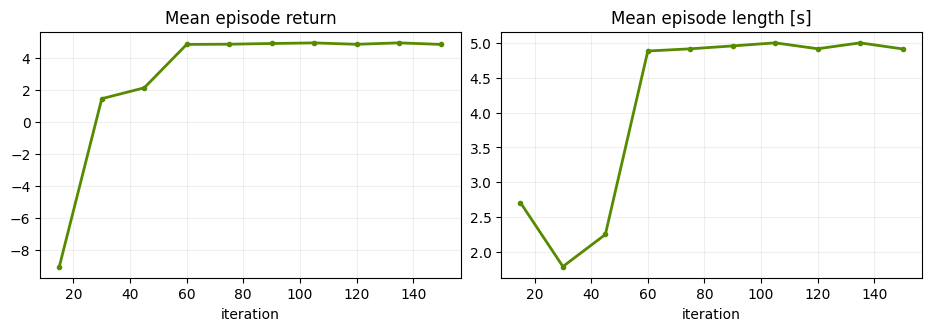

checkpoints in logs/cartpole_baseline/2026-11-18_15-34-04 : ['model_0.pt', 'model_100.pt', 'model_104.pt', 'model_119.pt', 'model_125.pt', 'model_134.pt', 'model_14.pt', 'model_149.pt', 'model_25.pt', 'model_29.pt', 'model_44.pt', 'model_50.pt', 'model_59.pt', 'model_74.pt', 'model_75.pt', 'model_89.pt']


In [56]:
import copy
from datetime import datetime

from isaaclab_tasks.utils.hydra import resolve_presets


def mean(values):
    values = list(values)
    return sum(values) / len(values) if values else float("nan")


def plot_logged_tags(axes, run_dir, writer, tags):
    # Plot TensorBoard scalars the RSL-RL logger wrote for every iteration (e.g. "Episode_Reward/feet_air_time").
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

    writer.flush()  # the logger only writes to disk every few seconds; force it now
    acc = EventAccumulator(str(run_dir), size_guidance={"scalars": 0})  # 0 = keep every point
    acc.Reload()
    available = set(acc.Tags()["scalars"])
    for ax, tag in zip(axes, tags):
        ax.clear()
        if tag in available:
            events = acc.Scalars(tag)
            ax.plot([e.step for e in events], [e.value for e in events], color="#2a6fb0", lw=1.5)
        else:
            ax.text(0.5, 0.5, "tag not logged (yet)", ha="center", va="center", transform=ax.transAxes)
        ax.axhline(0.0, color="gray", lw=0.8)  # makes the sign of a reward term easy to see
        ax.set(title=tag, xlabel="iteration")
        ax.title.set_fontsize(9)
        ax.grid(alpha=0.2)


def train(env_factory, env_cfg, agent_cfg, chunks=10, extra_metrics=None, log_tags=()):
    # Train with PPO, redrawing learning curves after each chunk. Returns (run_dir, history).
    # extra_metrics: {title: fn(env)} evaluated once per chunk (green curves).
    # log_tags: TensorBoard tags logged by RSL-RL every iteration, e.g. per-term rewards (blue curves).
    run_dir = ROOT / "logs" / agent_cfg.experiment_name / f"{datetime.now():%Y-%m-%d_%H-%M-%S}"
    chunk = max(1, agent_cfg.max_iterations // chunks)
    history = {"Mean episode return": [], "Mean episode length [s]": []}
    for name in extra_metrics or {}:
        history[name] = []
    n_plots = len(history) + len(log_tags)
    ncols = min(n_plots, 3)
    nrows = -(-n_plots // ncols)  # ceiling division
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.2 * nrows), layout="constrained", squeeze=False)
    axes = axes.ravel()
    for ax in axes[n_plots:]:
        ax.axis("off")
    handle = display(fig, display_id=True)
    plt.close(fig)
    iterations = []
    # work on a deep copy (so the caller's config is untouched), then pick the physics backend preset
    env_cfg = resolve_presets(copy.deepcopy(env_cfg), selected=("newton_mjwarp",))
    env_cfg.seed = agent_cfg.seed
    env_cfg.sim.visualizer_cfgs = []
    with quiet_simulation(), launch_simulation(env_cfg, SIM_ARGS):
        env = RslRlVecEnvWrapper(env_factory(env_cfg), clip_actions=agent_cfg.clip_actions)
        try:
            runner = make_runner(env, agent_cfg, log_dir=str(run_dir))
            for i in range(agent_cfg.max_iterations // chunk):
                runner.learn(num_learning_iterations=chunk, init_at_random_ep_len=(i == 0))
                runner.current_learning_iteration += 1  # learn() resumes from its last iteration
                iterations.append(runner.current_learning_iteration)
                history["Mean episode return"].append(mean(runner.logger.rewbuffer))
                history["Mean episode length [s]"].append(mean(runner.logger.lenbuffer) * env.unwrapped.step_dt)
                for name, fn in (extra_metrics or {}).items():
                    history[name].append(fn(env.unwrapped))
                for ax, (title, values) in zip(axes, history.items()):
                    ax.clear()
                    ax.plot(iterations, values, color="#568a00", lw=2, marker="o", ms=3)
                    ax.set(title=title, xlabel="iteration")
                    ax.grid(alpha=0.2)
                if log_tags:
                    plot_logged_tags(axes[len(history) :], run_dir, runner.logger.writer, log_tags)
                handle.update(fig)
        finally:
            env.close()
    print("checkpoints in", run_dir.relative_to(ROOT), ":", sorted(p.name for p in run_dir.glob("model_*.pt")))
    return run_dir, history


run_baseline, hist_baseline = train(MyCartpoleEnv, MyCartpoleEnvCfg(), make_agent_cfg("cartpole_baseline", 150))

## 4.7 Watch the policy

`play()` rebuilds the environment with **one** env and a camera, loads a checkpoint, and runs the policy.
`runner.get_inference_policy()` returns the **deterministic** policy (the Gaussian mean, no exploration
noise), which is what you would deploy on a robot. It also reports how much of the time the pole was upright.

Compare the **first** checkpoint (after one PPO update) with the **last**.

In [45]:
def checkpoints(run_dir):
    return sorted(run_dir.glob("model_*.pt"), key=lambda p: int(p.stem.split("_")[-1]))


def play_cartpole(checkpoint, env_cfg=None, agent_cfg=None, seconds=5.0, name=None):
    cfg = copy.deepcopy(env_cfg or MyCartpoleEnvCfg())
    cfg.scene.num_envs = 1
    cfg.scene.camera = video_camera()
    cfg.max_cart_pos = 100.0  # don't cut the video short if the cart drifts away
    cfg.seed = 7  # same starting state for every checkpoint we compare
    agent_cfg = agent_cfg or make_agent_cfg("play", 1)
    frames, upright = [], []
    with quiet_simulation(), launch_simulation(cfg, SIM_ARGS):
        env = RslRlVecEnvWrapper(MyCartpoleEnv(cfg), clip_actions=agent_cfg.clip_actions)
        try:
            runner = make_runner(env, agent_cfg)
            runner.load(str(checkpoint))
            policy = runner.get_inference_policy(device=env.unwrapped.device)
            base = env.unwrapped
            cam = base.scene["camera"]
            obs = env.get_observations()
            with torch.inference_mode():
                for step in range(int(seconds / base.step_dt)):
                    origin = base.scene.env_origins
                    cam.set_world_poses_from_view(
                        eyes=origin + torch.tensor([-5.5, 0.0, 2.2], device=base.device),
                        targets=origin + torch.tensor([0.0, 0.0, 1.8], device=base.device),
                    )
                    obs, _, dones, _ = env.step(policy(obs))
                    upright.append(abs(float(base.robot.data.joint_pos.torch[0, base.pole_idx[0]])) < 0.2)
                    if step % 2 == 0:  # 60 Hz policy -> 30 fps video
                        frames.append(cam.data.output["rgb"].torch[0, ..., :3].cpu().numpy())
        finally:
            env.close()
    print(f"{checkpoint.name}: pole upright {np.mean(upright):.0%} of the time")
    return save_video(frames, name or f"cartpole_{checkpoint.parent.parent.name}_{checkpoint.stem}")


ckpts = checkpoints(run_baseline)
play_cartpole(ckpts[0])
play_cartpole(ckpts[-1])

model_0.pt: pole upright 0% of the time


model_149.pt: pole upright 69% of the time


PosixPath('/home/andres/isaaclab/learning/videos/cartpole_cartpole_baseline_model_149.mp4')

## 4.8 Reading the training logs

RSL-RL writes **TensorBoard** logs next to the checkpoints. These curves are how you debug RL. The most
useful ones:

| Tag | What it tells you |
|---|---|
| `Train/mean_reward`, `Train/mean_episode_length` | is it learning at all? |
| `Loss/value` | critic error; should drop, spikes = the task changed (e.g. curriculum) |
| `Loss/surrogate` | PPO objective; small and noisy is normal |
| `Loss/entropy` | how random the policy still is |
| `Loss/learning_rate` | with `schedule="adaptive"`, falls if updates are too aggressive |
| `Policy/mean_std` | exploration noise $\sigma$; should shrink as the policy becomes confident |
| `Reward/*` (what we put in `extras["log"]`) | **each reward term separately**: which terms dominate? |
| `Perf/total_fps` | simulation + learning throughput (steps per second) |

(Manager-based tasks log their terms automatically as `Episode_Reward/*` and `Episode_Termination/*`.)

*Side note:* `train()` calls `runner.learn()` in chunks, and RSL-RL saves a checkpoint at the end of each
call, so you'll see a few extra checkpoints with "odd" iteration numbers besides the regular ones.

Let's load them directly from the log file:

available tags: Loss/entropy, Loss/learning_rate, Loss/surrogate, Loss/value, Perf/collection_time, Perf/learning_time, Perf/total_fps, Policy/mean_std, Reward/alive, Reward/cart_vel, Reward/pole_angle, Reward/pole_vel, Reward/terminated, Train/mean_episode_length, Train/mean_episode_length/time, Train/mean_reward, Train/mean_reward/time


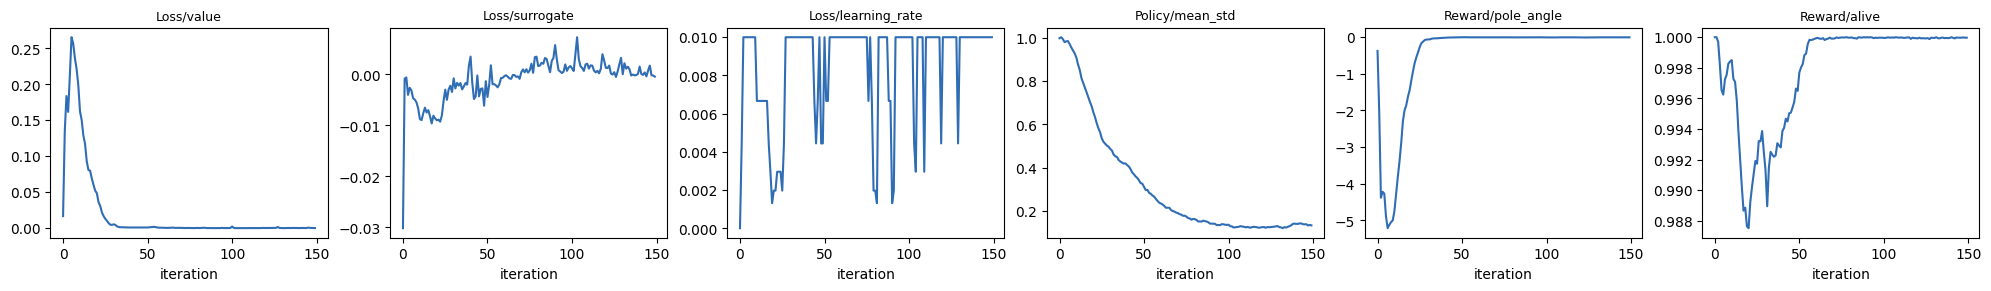

In [26]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator


def load_scalars(run_dir):
    acc = EventAccumulator(str(run_dir))
    acc.Reload()
    return {tag: ([e.step for e in acc.Scalars(tag)], [e.value for e in acc.Scalars(tag)]) for tag in acc.Tags()["scalars"]}


scalars = load_scalars(run_baseline)
print("available tags:", ", ".join(sorted(scalars)))

tags = ["Loss/value", "Loss/surrogate", "Loss/learning_rate", "Policy/mean_std", "Reward/pole_angle", "Reward/alive"]
fig, axes = plt.subplots(1, len(tags), figsize=(3.3 * len(tags), 2.8), layout="constrained")
for ax, tag in zip(np.atleast_1d(axes), tags):
    ax.plot(*scalars[tag], color="#2f6db5")
    ax.set_title(tag, fontsize=9)
    ax.set_xlabel("iteration")
plt.show()

## 4.9 Experiment: what happens if the reward is badly designed?

Reward design is the core skill in robot RL, and the most common interview topic. Our reward has an
**alive bonus** (+1 per step) and a **pole-angle penalty**. Note that the episode does **not** end when the
pole falls (only when the cart leaves the track).

**Predict first:** we set `rew_pole_angle = 0` (remove the pole penalty) and train again.
What will the policy do? Will the mean episode return still look good?

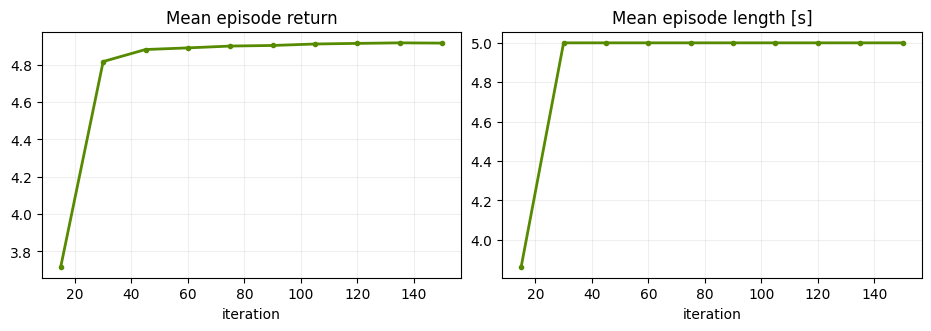

checkpoints in logs/cartpole_no_pole_penalty/2026-11-18_14-54-00 : ['model_0.pt', 'model_100.pt', 'model_104.pt', 'model_119.pt', 'model_125.pt', 'model_134.pt', 'model_14.pt', 'model_149.pt', 'model_25.pt', 'model_29.pt', 'model_44.pt', 'model_50.pt', 'model_59.pt', 'model_74.pt', 'model_75.pt', 'model_89.pt']
model_149.pt: pole upright 0% of the time


PosixPath('/home/andres/isaaclab/learning/videos/cartpole_cartpole_no_pole_penalty_model_149.mp4')

In [27]:
cfg_no_pole = MyCartpoleEnvCfg()
cfg_no_pole.rew_pole_angle = 0.0  # <- the only change

run_no_pole, hist_no_pole = train(MyCartpoleEnv, cfg_no_pole, make_agent_cfg("cartpole_no_pole_penalty", 150))
play_cartpole(checkpoints(run_no_pole)[-1], env_cfg=cfg_no_pole)

**What happened:** the return is still high and episodes reach the time-out, so by the numbers training
"succeeded". But the policy does **not** balance the pole: nothing in the reward asks for it. Staying alive
only requires keeping the cart on the track, which is much easier with the pole hanging down. This is
**reward hacking**: the policy optimises *exactly* what you wrote, not what you meant. That's why you should
always **watch the videos**, not only the curves.

**Fix 2: change the termination instead of the reward.** If the episode *ends* when the pole falls past
45°, the alive bonus becomes a balancing incentive again, even without the angle penalty. Terminations are a
powerful reward-design tool: they cut off all future rewards.

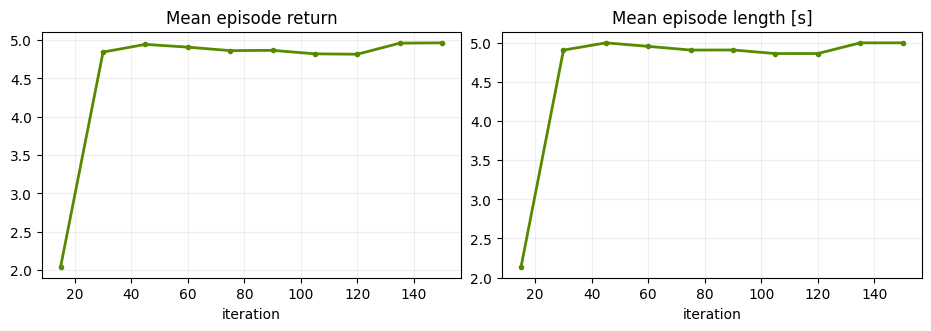

checkpoints in logs/cartpole_terminate_on_fall/2026-11-18_14-55-10 : ['model_0.pt', 'model_100.pt', 'model_104.pt', 'model_119.pt', 'model_125.pt', 'model_134.pt', 'model_14.pt', 'model_149.pt', 'model_25.pt', 'model_29.pt', 'model_44.pt', 'model_50.pt', 'model_59.pt', 'model_74.pt', 'model_75.pt', 'model_89.pt']
model_149.pt: pole upright 73% of the time


PosixPath('/home/andres/isaaclab/learning/videos/cartpole_cartpole_terminate_on_fall_model_149.mp4')

In [28]:
cfg_terminate = MyCartpoleEnvCfg()
cfg_terminate.rew_pole_angle = 0.0
cfg_terminate.max_pole_angle = math.pi / 4  # <- end the episode when the pole falls past 45 degrees

run_terminate, hist_terminate = train(MyCartpoleEnv, cfg_terminate, make_agent_cfg("cartpole_terminate_on_fall", 150))
play_cartpole(checkpoints(run_terminate)[-1], env_cfg=cfg_terminate)

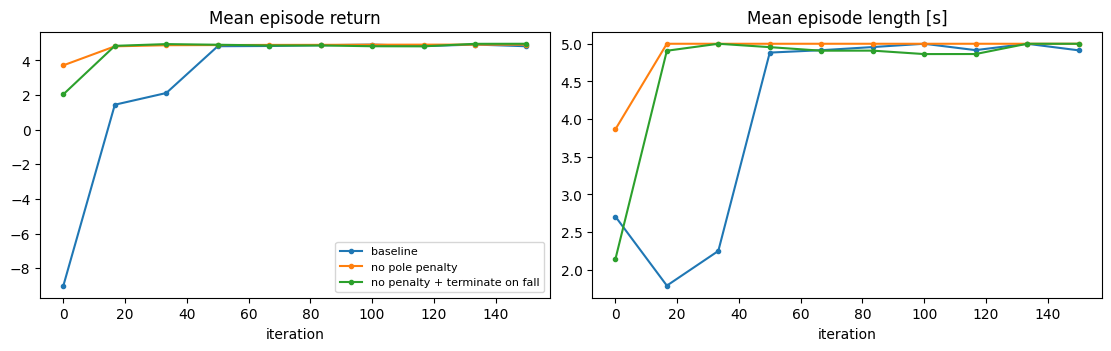

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained")
for label, hist in [("baseline", hist_baseline), ("no pole penalty", hist_no_pole), ("no penalty + terminate on fall", hist_terminate)]:
    for ax, key in zip(axes, ["Mean episode return", "Mean episode length [s]"]):
        ax.plot(np.linspace(0, 150, len(hist[key])), hist[key], marker="o", ms=3, label=label)
        ax.set(title=key, xlabel="iteration")
axes[0].legend(fontsize=8)
plt.show()

Note that the three returns are **not comparable**: they are different reward functions. In RL you compare
policies with a **task metric** you care about (here: *"% of time upright"*, printed above each video), not
with the reward.

**Exercises:**
1. Set `initial_pole_angle_range` to `(-0.05, 0.05)`. Does training get faster? Does the policy still recover from a big push?
2. Make `rew_cart_vel` much larger (e.g. `-1.0`). What trade-off appears?
3. Reduce `num_envs` to 256. How does training speed and quality change? (This is *why* GPU parallelism matters.)

---
# Part 5 — The Manager-based workflow: teach a Go2 to walk

## 5.1 Same MDP, written as terms

For real robots, Direct classes get long and hard to reuse. The **manager-based** workflow splits the MDP
into small reusable **terms**, each a function plus parameters, listed in config classes. Managers call
them for you:

| Direct method (Part 4) | Manager | Config section | Example term |
|---|---|---|---|
| `_get_observations` | ObservationManager | `observations` | `base_lin_vel`, `joint_pos_rel`, `height_scan` |
| `_pre_physics_step` / `_apply_action` | ActionManager | `actions` | `JointPositionAction(scale=0.25)` |
| `_get_rewards` | RewardManager | `rewards` | `track_lin_vel_xy_exp` (weight 1.5) |
| `_get_dones` | TerminationManager | `terminations` | `time_out`, `illegal_contact` (body touches ground) |
| `_reset_idx` | EventManager (mode `reset`) | `events` | `reset_root_state_uniform` |
| *(randomization)* | EventManager (`startup` / `interval`) | `events` | mass, friction, random pushes |
| *(goal)* | CommandManager | `commands` | random target velocity |
| *(difficulty)* | CurriculumManager | `curriculum` | `terrain_levels` |

This is the workflow of all the locomotion tasks, and the one we will extend for **parkour** (new terrain,
new reward terms). The task is **velocity tracking**: follow a commanded forward/sideways/turning speed.
Let's inspect the Go2 flat-ground task without running anything:

In [52]:
from isaaclab_tasks.core.velocity.config.go2.agents.rsl_rl_ppo_cfg import UnitreeGo2FlatPPORunnerCfg
from isaaclab_tasks.core.velocity.config.go2.flat_env_cfg import UnitreeGo2FlatEnvCfg


def active_terms(group):
    return {name: term for name, term in vars(group).items() if term is not None and hasattr(term, "func")}


go2_cfg = UnitreeGo2FlatEnvCfg()
print(f"timing: physics dt={go2_cfg.sim.dt}s, decimation={go2_cfg.decimation} -> policy at {1 / (go2_cfg.sim.dt * go2_cfg.decimation):.0f} Hz, episodes {go2_cfg.episode_length_s}s")
print("\nCOMMANDS:", go2_cfg.commands.base_velocity.ranges)
print("\nOBSERVATIONS (actor input, in order):", ", ".join(active_terms(go2_cfg.observations.policy)))
print("\nACTIONS:", {k: f"{type(v).__name__}(scale={v.scale})" for k, v in vars(go2_cfg.actions).items() if v is not None})
print("\nREWARDS (non-zero weights):")
for name, term in active_terms(go2_cfg.rewards).items():
    if term.weight != 0.0:
        print(f"   {name:24} {term.weight:+g}")
print("\nTERMINATIONS:", ", ".join(active_terms(go2_cfg.terminations)))
print("\nEVENTS (domain randomization):")
for name, term in active_terms(go2_cfg.events).items():
    print(f"   {term.mode:9} {name}")

timing: physics dt=0.005s, decimation=4 -> policy at 50 Hz, episodes 20.0s

COMMANDS: UniformVelocityCommandCfg.Ranges(lin_vel_x=(-1.0, 1.0), lin_vel_y=(-1.0, 1.0), ang_vel_z=(-1.0, 1.0), heading=(-3.141592653589793, 3.141592653589793))

OBSERVATIONS (actor input, in order): base_lin_vel, base_ang_vel, projected_gravity, velocity_commands, joint_pos, joint_vel, actions

ACTIONS: {'joint_pos': 'JointPositionActionCfg(scale=0.25)'}

REWARDS (non-zero weights):
   track_lin_vel_xy_exp     +1.5
   track_ang_vel_z_exp      +0.75
   lin_vel_z_l2             -2
   ang_vel_xy_l2            -0.05
   dof_torques_l2           -0.0002
   dof_acc_l2               -2.5e-07
   action_rate_l2           -0.005
   feet_air_time            +0.25
   flat_orientation_l2      -2.5
   base_height_l2           -30

TERMINATIONS: time_out, base_contact

EVENTS (domain randomization):
   startup   physics_material
   startup   add_base_mass
   startup   base_com
   reset     base_external_force_torque
   reset 

A term is just a function. Here is the main reward, velocity tracking with an exponential kernel
$r = \exp(-\lVert v_\text{cmd} - v \rVert^2 / \sigma^2)$: it is 1 for perfect tracking, decays smoothly, and is
always bounded, which makes it well-behaved for PPO.

In [53]:
import inspect

import isaaclab_tasks.core.velocity.mdp as velocity_mdp

print(inspect.getsource(velocity_mdp.track_lin_vel_xy_exp))

def track_lin_vel_xy_exp(
    env: ManagerBasedRLEnv, std: float, command_name: str, asset_cfg: SceneEntityCfg = SceneEntityCfg("robot")
) -> torch.Tensor:
    """Reward tracking of linear velocity commands (xy axes) using exponential kernel."""
    asset: RigidObject = env.scene[asset_cfg.name]
    lin_vel_error = torch.sum(
        torch.square(env.command_manager.get_command(command_name)[:, :2] - asset.data.root_lin_vel_b.torch[:, :2]),
        dim=1,
    )
    return torch.exp(-lin_vel_error / std**2)



## 5.2 Physics presets

Tasks declare their physics as a **preset**: a set of named alternatives (`newton_mjwarp`, `physx`, …).
`resolve_presets()` picks one. On the command line it's the `physics=newton_mjwarp` argument.

Now the camera. The policy never sees images; the camera is only for our videos. It follows the robot at a
fixed offset so the robot stays in frame as it walks.

In [54]:
from isaaclab.envs import ManagerBasedRLEnv

from isaaclab_tasks.utils.hydra import resolve_presets
from isaaclab_tasks.utils.presets import MultiBackendRendererCfg

PHYSICS, RENDERER = "newton_mjwarp", "newton_renderer"


def follow_camera(env, offset=(2.0, -2.0, 1.0)):
    scene = env.unwrapped.scene
    target = scene["robot"].data.root_pos_w.torch.clone()
    target[:, 2] = 0.3
    scene["camera"].set_world_poses_from_view(eyes=target + torch.tensor(offset, device=target.device), targets=target)


def go2_recording_cfg():
    cfg = UnitreeGo2FlatEnvCfg()
    cam = video_camera()
    cam.renderer_cfg = MultiBackendRendererCfg(newton_renderer=NewtonWarpRendererCfg(enable_shadows=True))
    cfg.scene.camera = cam
    cfg = resolve_presets(cfg, selected=(PHYSICS, RENDERER))
    cfg.play_mode()  # evaluation settings: no random pushes, etc.
    cfg.scene.num_envs = 1
    cfg.sim.visualizer_cfgs = []
    cfg.seed = 3
    return cfg


def play_go2(checkpoint=None, seconds=6.0, name="go2"):
    # Run a checkpoint (or zero actions if None) and record a video.
    cfg = go2_recording_cfg()
    agent_cfg = UnitreeGo2FlatPPORunnerCfg()
    frames = []
    with quiet_simulation(), launch_simulation(cfg, SIM_ARGS):
        env = RslRlVecEnvWrapper(ManagerBasedRLEnv(cfg), clip_actions=agent_cfg.clip_actions)
        try:
            if checkpoint is not None:
                runner = make_runner(env, agent_cfg)
                runner.load(str(checkpoint))
                policy = runner.get_inference_policy(device=env.unwrapped.device)
            else:
                policy = lambda obs: torch.zeros(env.action_space.shape, device=env.unwrapped.device)
            obs = env.get_observations()
            with torch.inference_mode():
                for step in range(int(seconds / env.unwrapped.step_dt)):
                    follow_camera(env)
                    obs, _, _, _ = env.step(policy(obs))
                    if step % 2 == 0:  # 50 Hz policy -> 25 fps
                        frames.append(env.unwrapped.scene["camera"].data.output["rgb"].torch[0, ..., :3].cpu().numpy())
        finally:
            env.close()
    return save_video(frames, name, fps=25)


play_go2(None, seconds=2.0, name="go2_zero_actions")

PosixPath('/home/andres/isaaclab/learning/videos/go2_zero_actions.mp4')

With zero actions the PD controllers just hold the default joint angles (action 0 = default pose, because
`use_default_offset=True`), so the robot stays in its slightly crouched default stance without moving. Now let's train it to walk.

## 5.3 Train the Go2 (≈ 4–6 min)

Same `train()` helper as for the cartpole, only the environment class (`ManagerBasedRLEnv`) and configs
change. **4096 robots** train in parallel. We additionally plot the **velocity tracking error**, a task
metric that, unlike the reward, has a physical meaning.

**About the number of iterations:** 300 is the official default for this task, but with the Newton backend
the policy often ends in a **local optimum: standing still** (it first spends ~100 iterations learning not to
fall). The velocity error then stays ≈ 0.7 m/s, about the size of the command itself. Try 1000 (≈ 13 min).

The **blue** plots are read live from the run's TensorBoard log (one point per iteration). What to look for:

| Plot | Standing still | Walking |
|---|---|---|
| Velocity error (green) | stuck ≈ 0.7 m/s | drops well below (≈ 0.2–0.3) |
| `track_lin_vel_xy_exp` | ≈ 0.35 (partial reward for standing) | rises towards its max of 1.5 |
| `feet_air_time` | slightly **negative** (only short shuffles) | turns **positive** (proper steps) |
| `base_contact` termination | — | low: the fraction of episodes ending with the trunk on the ground |
| `mean_std` | — | exploration noise; if it collapses early, the policy stops trying new things |

Per-term rewards are logged as *episode sum ÷ maximum episode length (20 s)*, so a tracking term reaches its
weight only for perfect tracking over a full-length episode; episodes that end early also pull it down.

samples per iteration: 98,304


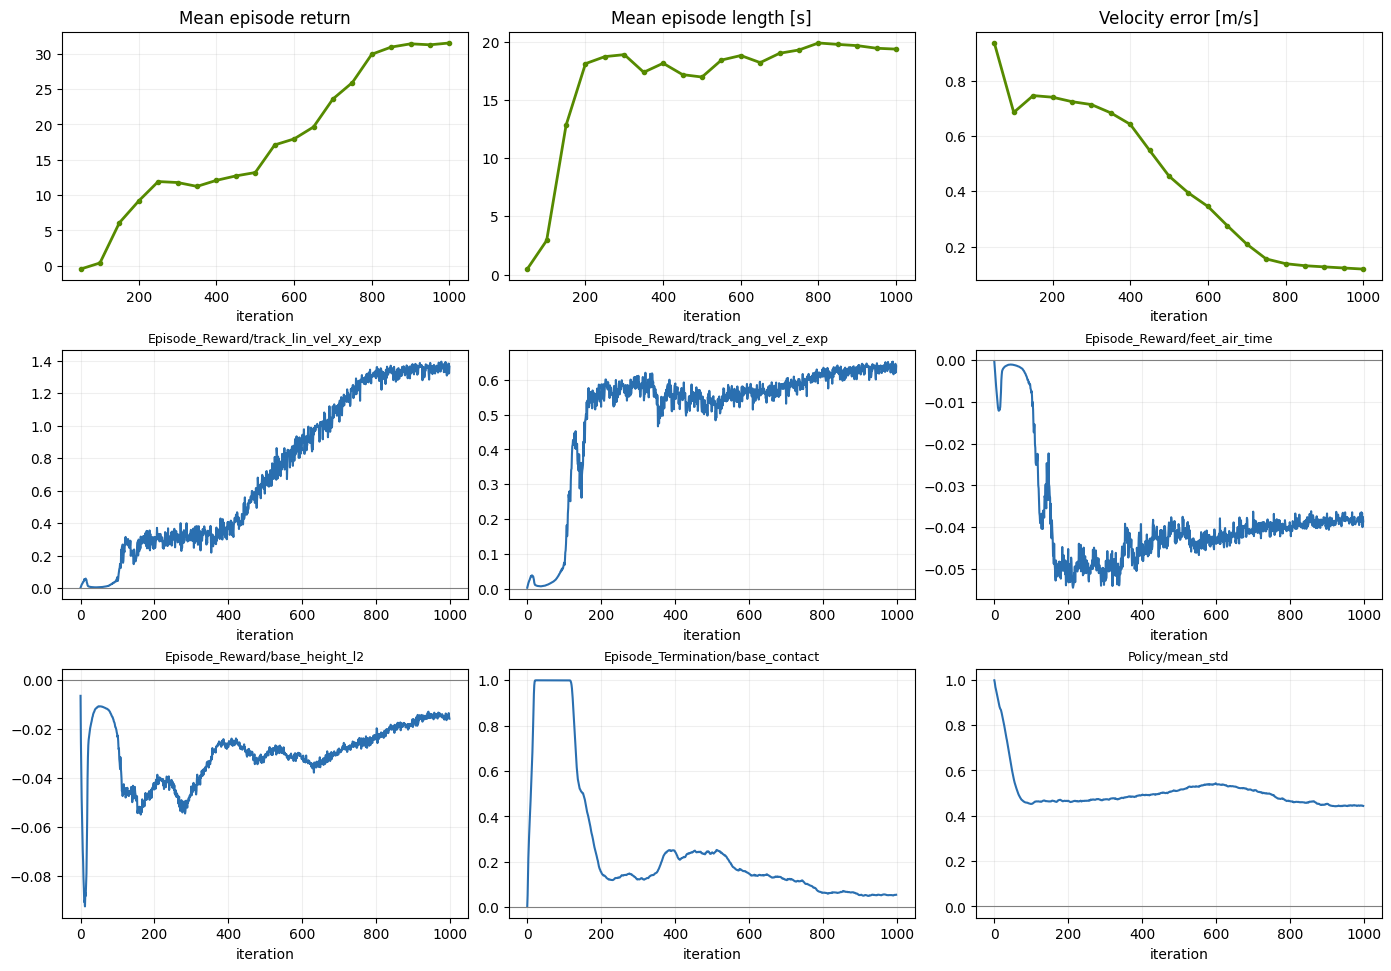

checkpoints in logs/go2_flat/2026-11-18_15-34-39 : ['model_0.pt', 'model_100.pt', 'model_149.pt', 'model_150.pt', 'model_199.pt', 'model_200.pt', 'model_249.pt', 'model_250.pt', 'model_299.pt', 'model_300.pt', 'model_349.pt', 'model_350.pt', 'model_399.pt', 'model_400.pt', 'model_449.pt', 'model_450.pt', 'model_49.pt', 'model_499.pt', 'model_50.pt', 'model_500.pt', 'model_549.pt', 'model_550.pt', 'model_599.pt', 'model_600.pt', 'model_649.pt', 'model_650.pt', 'model_699.pt', 'model_700.pt', 'model_749.pt', 'model_750.pt', 'model_799.pt', 'model_800.pt', 'model_849.pt', 'model_850.pt', 'model_899.pt', 'model_900.pt', 'model_949.pt', 'model_950.pt', 'model_99.pt', 'model_999.pt']


In [57]:
go2_agent = UnitreeGo2FlatPPORunnerCfg()
go2_agent.experiment_name = "go2_flat"
go2_agent.max_iterations = 1000  # official default; try 1000 (see above)
go2_train_cfg = UnitreeGo2FlatEnvCfg()  # train() picks the physics preset


def velocity_error(env):
    robot = env.scene["robot"]
    cmd = env.command_manager.get_command("base_velocity")[:, :2]
    return (cmd - robot.data.root_lin_vel_b.torch[:, :2]).norm(dim=1).mean().item()


# TensorBoard tags to plot live. Any tag works: run `load_scalars(run_go2).keys()` afterwards to see them all.
GO2_LOG_TAGS = [
    "Episode_Reward/track_lin_vel_xy_exp",
    "Episode_Reward/track_ang_vel_z_exp",
    "Episode_Reward/feet_air_time",
    "Episode_Reward/base_height_l2",
    "Episode_Termination/base_contact",
    "Policy/mean_std",
]

print(f"samples per iteration: {go2_train_cfg.scene.num_envs * go2_agent.num_steps_per_env:,}")
run_go2, hist_go2 = train(
    ManagerBasedRLEnv,
    go2_train_cfg,
    go2_agent,
    chunks=20,  # redraw 20 times during training
    extra_metrics={"Velocity error [m/s]": velocity_error},
    log_tags=GO2_LOG_TAGS,
)

## 5.4 Compare checkpoints

In [58]:
go2_ckpts = checkpoints(run_go2)
play_go2(go2_ckpts[0], name="go2_first_checkpoint")
play_go2(go2_ckpts[-1], name="go2_last_checkpoint")

PosixPath('/home/andres/isaaclab/learning/videos/go2_last_checkpoint.mp4')

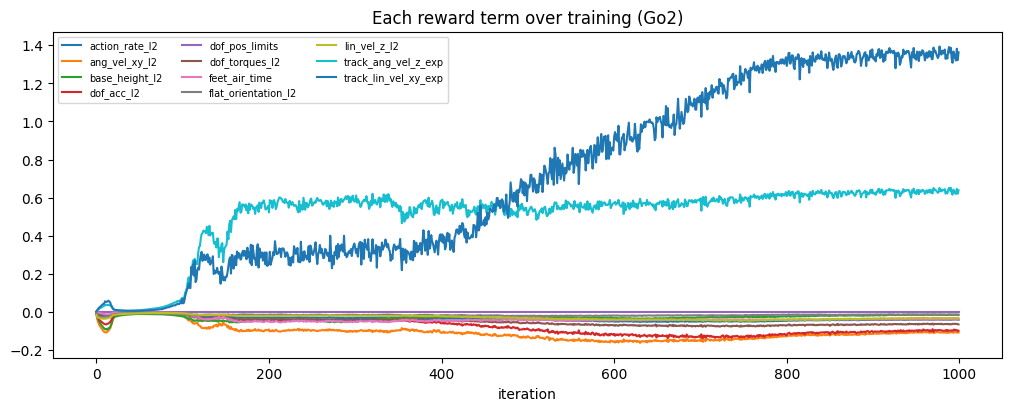

In [59]:
scalars = load_scalars(run_go2)
reward_tags = sorted(t for t in scalars if t.startswith("Episode_Reward/"))
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for tag in reward_tags:
    ax.plot(*scalars[tag], label=tag.split("/")[-1])
ax.set(title="Each reward term over training (Go2)", xlabel="iteration")
ax.legend(fontsize=7, ncol=3)
plt.show()

**How to read this:** the tracking terms grow (the robot learns to follow commands), while penalty terms
(torques, action rate…) typically get *more* negative at first (it moves more), then stabilise. If one
penalty dominates everything, the policy will learn to stand still: a classic tuning problem.

**Exercises:**
1. In `go2_train_cfg`, set `rewards.feet_air_time.weight = 0.0` and retrain. How does the gait change?
2. Remove the `base_lin_vel` observation (`observations.policy.base_lin_vel = None`). Real robots can't measure
   it directly; does the policy still learn? (This is a real sim-to-real design question.)
3. Change `commands.base_velocity.ranges.lin_vel_x` to `(1.0, 2.0)`: can it learn to run?

---
# Part 6 — The terminal workflow

The notebook is great for learning. For long trainings (rough terrain, parkour: 30+ minutes) you use the
command line, in your Ubuntu terminal, from `~/isaaclab/IsaacLab`:

```bash
# list all registered tasks
uv run isaaclab list_envs

# train (headless: no window)
uv run isaaclab train --rl_library rsl_rl --task Isaac-Velocity-Flat-UnitreeGo2 physics=newton_mjwarp

# override settings without editing code
uv run isaaclab train --rl_library rsl_rl --task Isaac-Velocity-Flat-UnitreeGo2 --num_envs 2048 --max_iterations 500 --seed 1

# replay the latest checkpoint in a viewer window, or record a video
uv run isaaclab play --rl_library rsl_rl --task Isaac-Velocity-Flat-UnitreeGo2 --num_envs 16 --viz newton_gl
uv run isaaclab play --rl_library rsl_rl --task Isaac-Velocity-Flat-UnitreeGo2 --num_envs 16 --video

# watch training curves in your browser (http://localhost:6006)
uv run tensorboard --logdir logs
```

Runs are saved in `logs/rsl_rl/<experiment_name>/<date_time>/`: checkpoints `model_<iteration>.pt`, the
exact configs used (`params/`), and the TensorBoard event file.

A task becomes available to the CLI by being **registered** with gymnasium (see
`source/isaaclab_tasks/.../config/go2/__init__.py`): a task ID is linked to an env config and an agent config.
For the parkour project we will create our own package with its own registered tasks.

---
# Part 7 — Recap and interview questions

**What you did:** built a scene and stepped physics by hand, wrote a complete RL environment (Direct
workflow), trained it with PPO via RSL-RL, read its logs, broke the reward and fixed it, then trained a
quadruped with the manager-based workflow and domain randomization.

**Questions you should now be able to answer** (answers in short):

1. **Why PPO for robot RL?** Simple and stable (clipped updates), and it scales with massively parallel
   simulation; off-policy methods (SAC) are more sample-efficient but harder to scale to thousands of envs.
2. **What does the clip do?** Removes the incentive to move the action probability ratio beyond $1\pm\epsilon$
   on the current batch, giving a cheap trust region.
3. **What is GAE's λ?** Bias–variance trade-off between one-step TD (λ=0) and Monte-Carlo (λ=1) advantages.
4. **Why does the critic exist?** As a baseline to compute advantages (lower variance gradients); it is not
   used at deployment.
5. **Why joint position targets as actions instead of torques?** The PD loop gives a stable, smooth
   low-level behaviour, the policy learns faster, and it transfers better to hardware.
6. **What is decimation?** Physics runs faster (200 Hz) than the policy (50 Hz): each action is held for
   `decimation` physics steps.
7. **Termination vs time-out?** Termination = failure (no future value: bootstrapping stops). Time-out = the
   episode was cut artificially, so the value of the last state is still bootstrapped.
8. **What is domain randomization and why?** Randomizing mass, friction, pushes, sensor noise in sim so the
   policy is robust to the sim-to-real gap.
9. **What is a curriculum?** Increasing task difficulty (terrain level) as the policy improves, so it gets
   useful learning signal at every stage.
10. **How do you debug a policy that doesn't learn?** Check env with random actions; look at per-term
    rewards (is a penalty dominating?); check episode length and terminations; watch videos for reward hacking;
    check the noise std and learning rate curves.
11. **Direct vs manager-based?** Direct: one class, full control. Manager-based: modular terms, easy to
    reuse and ablate. Locomotion uses manager-based.
12. **What is an asymmetric actor-critic?** The critic gets privileged information (e.g. true friction,
    terrain) that the actor doesn't, since only the actor is deployed.

**Next notebook:** rough terrain with a height scanner and a terrain curriculum, then parkour.